Load and preprocess Fashion-MNIST dataset

Train images shape: (60000, 28, 28)
Train labels shape: (60000,)
Test images shape: (10000, 28, 28)
Test labels shape: (10000,)
Sample label (numeric): 1


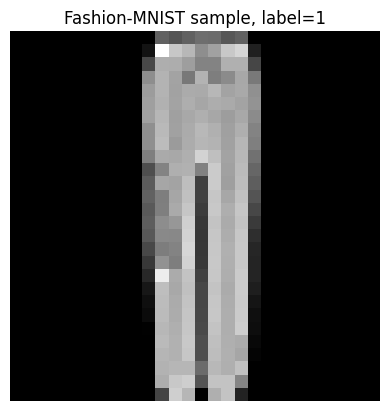

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Reproducibility (simple + enough for demo)
tf.random.set_seed(42)
np.random.seed(42)

from tensorflow.keras.datasets import fashion_mnist

# Load data (Lecture 2 style)
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

print("Train images shape:", x_train.shape)
print("Train labels shape:", y_train.shape)
print("Test images shape:", x_test.shape)
print("Test labels shape:", y_test.shape)

# Normalize like Lecture 2
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

# Quick sanity check: show one sample
k = 1000
print("Sample label (numeric):", y_train[k])
plt.figure()
plt.imshow(x_train[k], cmap="gray")
plt.title(f"Fashion-MNIST sample, label={y_train[k]}")
plt.axis("off")
plt.show()

Baseline model: Single-layer neural network with 1 unit

In [2]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

# Model 1: Single layer with 1 unit (Lecture 2 baseline)
model_single_1 = Sequential()
model_single_1.add(Flatten(input_shape=(28, 28)))
model_single_1.add(Dense(1, activation='relu', kernel_initializer='he_normal'))
model_single_1.add(Dense(10, activation='softmax'))

model_single_1.summary()

model_single_1.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_single_1 = model_single_1.fit(
    x_train, y_train,
    epochs=20,
    batch_size=128,
    validation_data=(x_test, y_test),
    verbose=1
)

loss1, acc1 = model_single_1.evaluate(x_test, y_test, verbose=0)
print("Single-layer (1 unit) Test loss:", loss1)
print("Single-layer (1 unit) Test accuracy:", acc1)

c:\Users\hasan\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           785 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │            20 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 805 (3.14 KB)

 Trainable params: 805 (3.14 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.1978 - loss: 2.0245 - val_accuracy: 0.2258 - val_loss: 1.8713
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2506 - loss: 1.8117 - val_accuracy: 0.2824 - val_loss: 1.7647
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2899 - loss: 1.7260 - val_accuracy: 0.3045 - val_loss: 1.6969
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3096 - loss: 1.6689 - val_accuracy: 0.3224 - val_loss: 1.6496
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3222 - loss: 1.6284 - val_accuracy: 0.3364 - val_loss: 1.6149
Epoch 6/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3323 - loss: 1.5980 - val_accuracy: 0.3481 - val_loss: 1.5882
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3426 - loss: 1.5740 - val_accuracy: 0.3553 - val_loss: 1.5666
Epoch 8/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3514 - loss: 1.5544 - val_accuracy: 0.

Improved single-layer model: 10 hidden units

In [3]:
# Improved single-layer model: 10 units
model_single_10 = Sequential()
model_single_10.add(Flatten(input_shape=(28, 28)))
model_single_10.add(Dense(10, activation='relu', kernel_initializer='he_normal'))
model_single_10.add(Dense(10, activation='softmax'))

model_single_10.summary()

model_single_10.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_single_10 = model_single_10.fit(
    x_train, y_train,
    epochs=20,
    batch_size=128,
    validation_data=(x_test, y_test),
    verbose=1
)

loss2, acc2 = model_single_10.evaluate(x_test, y_test, verbose=0)
print("Single-layer (10 units) Test loss:", loss2)
print("Single-layer (10 units) Test accuracy:", acc2)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         7,850 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,960 (31.09 KB)

 Trainable params: 7,960 (31.09 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6180 - loss: 1.1069 - val_accuracy: 0.7775 - val_loss: 0.6412
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8083 - loss: 0.5497 - val_accuracy: 0.8154 - val_loss: 0.5294
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8313 - loss: 0.4823 - val_accuracy: 0.8268 - val_loss: 0.4938
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8403 - loss: 0.4537 - val_accuracy: 0.8318 - val_loss: 0.4779
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8454 - loss: 0.4373 - val_accuracy: 0.8359 - val_loss: 0.4674
Epoch 6/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8496 - loss: 0.4261 - val_accuracy: 0.8381 - val_loss: 0.4601
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8527 - loss: 0.4178 - val_accuracy: 0.8386 - val_loss: 0.4559
Epoch 8/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8550 - loss: 0.4112 - val_accuracy: 0.

Multi-Layer Perceptron (MLP): two hidden layers, no dropout

In [4]:
from tensorflow.keras.layers import Dropout

# MLP without dropout
model_mlp = Sequential()
model_mlp.add(Flatten(input_shape=(28, 28)))
model_mlp.add(Dense(512, activation='relu', kernel_initializer='he_normal'))
model_mlp.add(Dense(512, activation='relu', kernel_initializer='he_normal'))
model_mlp.add(Dense(10, activation='softmax'))

model_mlp.summary()

model_mlp.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_mlp = model_mlp.fit(
    x_train, y_train,
    epochs=20,
    batch_size=128,
    validation_data=(x_test, y_test),
    verbose=1
)

loss3, acc3 = model_mlp.evaluate(x_test, y_test, verbose=0)
print("MLP (no dropout) Test loss:", loss3)
print("MLP (no dropout) Test accuracy:", acc3)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 669,706 (2.55 MB)

 Trainable params: 669,706 (2.55 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.8328 - loss: 0.4688 - val_accuracy: 0.8524 - val_loss: 0.4020
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8737 - loss: 0.3482 - val_accuracy: 0.8660 - val_loss: 0.3709
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8847 - loss: 0.3096 - val_accuracy: 0.8719 - val_loss: 0.3521
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8930 - loss: 0.2860 - val_accuracy: 0.8756 - val_loss: 0.3517
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9006 - loss: 0.2641 - val_accuracy: 0.8766 - val_loss: 0.3489
Epoch 6/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9070 - loss: 0.2469 - val_accuracy: 0.8800 - val_loss: 0.3571
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9130 - loss: 0.2328 - val_accuracy: 0.8813 - val_loss: 0.3511
Epoch 8/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9165 - loss: 0.2209 - val_accu

Multi-Layer Perceptron (MLP): two hidden layers with dropout

In [5]:
# MLP with dropout (regularization)
model_mlp_dropout = Sequential()
model_mlp_dropout.add(Flatten(input_shape=(28, 28)))
model_mlp_dropout.add(Dense(512, activation='relu', kernel_initializer='he_normal'))
model_mlp_dropout.add(Dropout(0.2))
model_mlp_dropout.add(Dense(512, activation='relu', kernel_initializer='he_normal'))
model_mlp_dropout.add(Dropout(0.2))
model_mlp_dropout.add(Dense(10, activation='softmax'))

model_mlp_dropout.summary()

model_mlp_dropout.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_mlp_dropout = model_mlp_dropout.fit(
    x_train, y_train,
    epochs=20,
    batch_size=128,
    validation_data=(x_test, y_test),
    verbose=1
)

loss4, acc4 = model_mlp_dropout.evaluate(x_test, y_test, verbose=0)
print("MLP (with dropout) Test loss:", loss4)
print("MLP (with dropout) Test accuracy:", acc4)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 669,706 (2.55 MB)

 Trainable params: 669,706 (2.55 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.8137 - loss: 0.5189 - val_accuracy: 0.8554 - val_loss: 0.4049
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.8597 - loss: 0.3844 - val_accuracy: 0.8612 - val_loss: 0.3868
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.8711 - loss: 0.3507 - val_accuracy: 0.8612 - val_loss: 0.3728
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.8792 - loss: 0.3278 - val_accuracy: 0.8674 - val_loss: 0.3632
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.8852 - loss: 0.3098 - val_accuracy: 0.8709 - val_loss: 0.3469
Epoch 6/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.8898 - loss: 0.2959 - val_accuracy: 0.8760 - val_loss: 0.3419
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.8930 - loss: 0.2856 - val_accuracy: 0.8758 - val_loss: 0.3425
Epoch 8/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.8962 - loss: 0.2773 - val_accu

Comparison table for Fashion-MNIST models (loss + accuracy + hyperparameters)

In [6]:
import pandas as pd

results = pd.DataFrame([
    {
        "Model": "Single-layer (1 unit)",
        "Hidden layers": 1,
        "Units": "1",
        "Dropout": "No",
        "Optimizer": "Adam",
        "Loss": "sparse_categorical_crossentropy",
        "Epochs": 20,
        "Batch size": 128,
        "Test loss": loss1,
        "Test accuracy": acc1
    },
    {
        "Model": "Single-layer (10 units)",
        "Hidden layers": 1,
        "Units": "10",
        "Dropout": "No",
        "Optimizer": "Adam",
        "Loss": "sparse_categorical_crossentropy",
        "Epochs": 20,
        "Batch size": 128,
        "Test loss": loss2,
        "Test accuracy": acc2
    },
    {
        "Model": "MLP (512+512)",
        "Hidden layers": 2,
        "Units": "512, 512",
        "Dropout": "No",
        "Optimizer": "Adam",
        "Loss": "sparse_categorical_crossentropy",
        "Epochs": 20,
        "Batch size": 128,
        "Test loss": loss3,
        "Test accuracy": acc3
    },
    {
        "Model": "MLP (512+512) + Dropout(0.2)",
        "Hidden layers": 2,
        "Units": "512, 512",
        "Dropout": "Yes (0.2, 0.2)",
        "Optimizer": "Adam",
        "Loss": "sparse_categorical_crossentropy",
        "Epochs": 20,
        "Batch size": 128,
        "Test loss": loss4,
        "Test accuracy": acc4
    }
])

results

,Model,Hidden layers,Units,Dropout,Optimizer,Loss,Epochs,Batch size,Test loss,Test accuracy
0,Single-layer (1 unit),1,1,No,Adam,sparse_categorical_crossentropy,20,128,1.450808,0.3956
1,Single-layer (10 units),1,10,No,Adam,sparse_categorical_crossentropy,20,128,0.424043,0.8482
2,MLP (512+512),2,"512, 512",No,Adam,sparse_categorical_crossentropy,20,128,0.486945,0.8819
3,MLP (512+512) + Dropout(0.2),2,"512, 512","Yes (0.2, 0.2)",Adam,sparse_categorical_crossentropy,20,128,0.354788,0.8857
